# Punto (c): análisis preliminar e información adicional de contexto
## Retrasos de vuelos domésticos en EE. UU. (2016–2018)

El EDA mostró **qué** pasa (cuándo, dónde y con qué aerolínea hay más retraso). Este notebook revisa si la base tiene todo lo necesario para explicar **por qué**, y agrega la información de contexto que le falta:

| # | Información adicional | Para qué | Fuente |
|---|---|---|---|
| 1 | Tipo y marca de cada aerolínea | Comparar tradicionales, bajo costo y regionales; las regionales vuelan para otras marcas | Tabla construida a partir de los códigos de aerolínea |
| 2 | Festivos federales | Ver si los días festivos y sus alrededores cambian el volumen y el retraso | Librería `holidays` |
| 3 | Eventos extremos | Identificar los días atípicos (tormentas, huracanes) que distorsionan promedios | Serie diaria de la propia base |
| 4 | Ubicación de los aeropuertos | Estado, región, coordenadas y zona horaria para mapas y comparaciones regionales | Librería `airportsdata` |
| 5 | Clima diario por aeropuerto | Medir el efecto real del clima, que la base subestima | Librería `meteostat` (estaciones meteorológicas) |

**Requisitos (una sola vez):**
```
pip install holidays airportsdata "meteostat<2"
```
La sección de clima necesita internet; si no hay conexión, el notebook la salta y sigue.

## 0. Librerías y configuración

In [10]:
from pathlib import Path
import json
import unicodedata
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import holidays
import airportsdata

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
sns.set_theme(style="whitegrid", palette="pastel")

ANIOS = [2016, 2017, 2018]
UMBRAL_RETRASO = 15
N_AEROPUERTOS_CLIMA = 30           # aeropuertos con más vuelos a los que se les busca el clima
PRIMER_GRAFICO, PRIMERA_TABLA = 20, 5   # continúa la numeración del informe (el EDA llega a Gráfico 19 y Tabla 4)

DATA_DIR = Path(".") if any(Path(".").glob("20*.csv")) else Path("Proyecto BD")
OUT_DIR = Path("salidas_contexto")
OUT_DIR.mkdir(exist_ok=True)

_cont = {"grafico": PRIMER_GRAFICO - 1, "tabla": PRIMERA_TABLA - 1}
HALLAZGOS = {}

def _archivo(prefijo, n, titulo):
    s = unicodedata.normalize("NFKD", titulo.lower()).encode("ascii", "ignore").decode()
    s = "".join(c if c.isalnum() else "_" for c in s).strip("_")
    return f"{prefijo}_{n:02d}_{s[:50]}"

def grafico(fig, titulo):
    _cont["grafico"] += 1
    n = _cont["grafico"]
    fig.suptitle(f"Gráfico {n}. {titulo}", fontsize=13, fontweight="bold")
    fig.tight_layout()
    fig.savefig(OUT_DIR / f"{_archivo('grafico', n, titulo)}.png", dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)

def tabla(df, titulo):
    _cont["tabla"] += 1
    n = _cont["tabla"]
    print(f"Tabla {n}. {titulo}")
    df.to_csv(OUT_DIR / f"{_archivo('tabla', n, titulo)}.csv")
    display(df)

print("Carpeta de datos:", DATA_DIR.resolve())

Carpeta de datos: C:\Users\User\Desktop\Proyecto BD


## 1. Carga ligera y agregados base

Solo se leen las columnas necesarias. Se construyen cuatro tablas agregadas: por día, por aeropuerto, por aerolínea y año, y por aeropuerto y día (esta última para cruzar con el clima).

In [11]:
CAUSAS = ["CARRIER_DELAY", "WEATHER_DELAY", "NAS_DELAY", "SECURITY_DELAY", "LATE_AIRCRAFT_DELAY"]
COLS = ["FL_DATE", "OP_CARRIER", "ORIGIN", "CANCELLED", "DIVERTED", "ARR_DELAY", "CANCELLATION_CODE"] + CAUSAS
DTYPES = {"OP_CARRIER": "category", "ORIGIN": "category", "CANCELLED": "float32", "DIVERTED": "float32",
          "ARR_DELAY": "float32", "CANCELLATION_CODE": "category", **{c: "float32" for c in CAUSAS}}

df = pd.concat([pd.read_csv(DATA_DIR / f"{a}.csv", usecols=COLS, dtype=DTYPES, parse_dates=["FL_DATE"])
                for a in ANIOS], ignore_index=True)
for c in ["OP_CARRIER", "ORIGIN", "CANCELLATION_CODE"]:
    df[c] = df[c].astype("category")
df["CANCELLED"] = df["CANCELLED"].fillna(0).astype("int8")
df["OPERADO"] = ((df["CANCELLED"] == 0) & (df["DIVERTED"].fillna(0) == 0)).astype("int8")
df = df[~((df["OPERADO"] == 1) & df["ARR_DELAY"].isna())]            # misma regla del EDA
df["RETRASADO"] = np.where(df["OPERADO"] == 1, (df["ARR_DELAY"] >= UMBRAL_RETRASO).astype("float32"), np.nan)
df.loc[(df["OPERADO"] == 1) & (df["ARR_DELAY"] < UMBRAL_RETRASO), CAUSAS] = 0
df["AÑO"] = df["FL_DATE"].dt.year.astype("int16")
print(f"{len(df):,} vuelos cargados")

def agregar(por):
    g = df.groupby(por, observed=True)
    t = pd.DataFrame({"vuelos": g.size(), "cancelados": g["CANCELLED"].sum(), "operados": g["OPERADO"].sum(),
                      "retrasados": g["RETRASADO"].sum(), **{f"min_{c}": g[c].sum() for c in CAUSAS}})
    t["tasa_retraso"] = t["retrasados"] / t["operados"] * 100
    t["tasa_cancelacion"] = t["cancelados"] / t["vuelos"] * 100
    return t

por_dia = agregar("FL_DATE").reset_index()
por_aeropuerto = agregar("ORIGIN").reset_index()
por_aerolinea = agregar(["OP_CARRIER", "AÑO"]).reset_index()
top_ap = por_aeropuerto.nlargest(N_AEROPUERTOS_CLIMA, "vuelos")["ORIGIN"].astype(str).tolist()
ap_dia = agregar(["ORIGIN", "FL_DATE"]).reset_index()
ap_dia = ap_dia[ap_dia["ORIGIN"].astype(str).isin(top_ap)]
canc_dia = df[df["CANCELLED"] == 1].groupby(["FL_DATE", "CANCELLATION_CODE"], observed=True).size().unstack(fill_value=0)
del df
print("Agregados listos:", len(por_dia), "días,", len(por_aeropuerto), "aeropuertos")

18,503,125 vuelos cargados
Agregados listos: 1096 días, 362 aeropuertos


## 2. Contexto 1: tipo y marca de las aerolíneas

La base solo trae un código de dos letras. Para interpretarlo se agrega el nombre, el **modelo de negocio** (tradicional, bajo costo o regional) y, para las regionales, las **marcas para las que vuelan**: un vuelo de SkyWest (OO), por ejemplo, se vende como Delta, United, American o Alaska. Sin esta información se culpa a la aerolínea regional de retrasos que el pasajero atribuye a la marca.

Códigos sin clasificar: ninguno
Tabla 5. Aerolíneas con su tipo y las marcas para las que vuelan


,,,,vuelos,tasa_retraso
OP_CARRIER,nombre,tipo,vuela_para,,
WN,Southwest Airlines,Bajo costo,Propia,3981440,19.23
DL,Delta Air Lines,Tradicional,Propia,2795589,13.46
AA,American Airlines,Tradicional,Propia,2727661,19.32
OO,SkyWest Airlines,Regional,"Delta, United, American, Alaska",2086597,17.98
UA,United Airlines,Tradicional,Propia,1751113,17.92
EV,ExpressJet Airlines,Regional,"United, Delta, American",1033421,19.27
B6,JetBlue Airways,Bajo costo,Propia,886137,25.88
AS,Alaska Airlines,Tradicional,Propia,608109,15.24
NK,Spirit Airlines,Bajo costo,Propia,471195,20.51


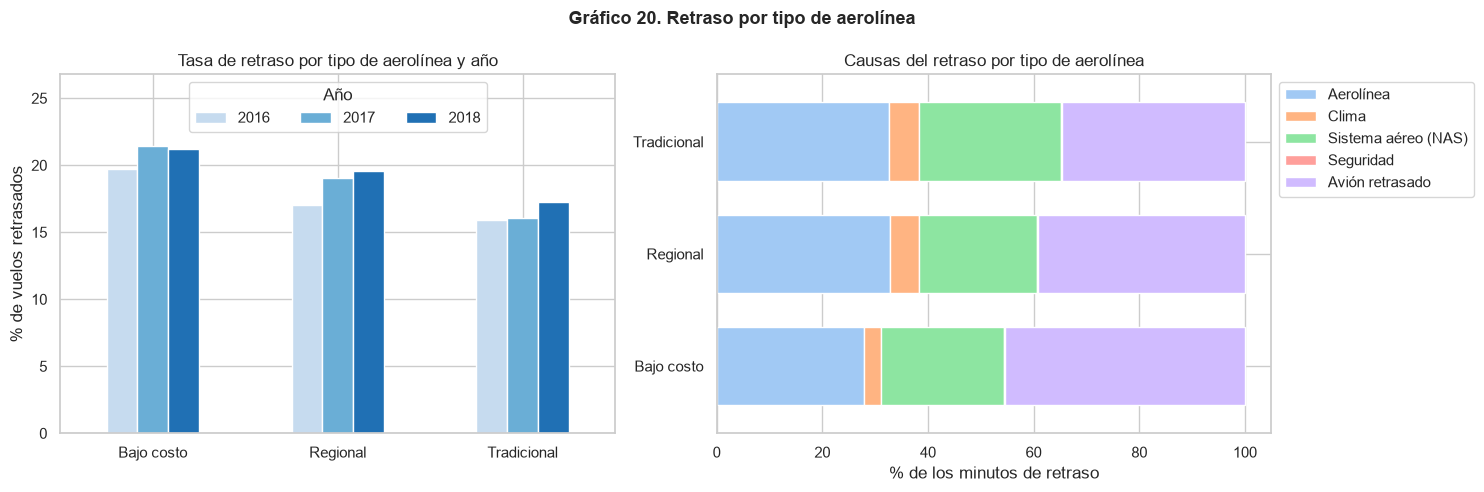

Tasa de retraso por tipo: {'Bajo costo': 20.82, 'Regional': 18.81, 'Tradicional': 16.41}
% de minutos por avión retrasado: {'Bajo costo': 45.400001525878906, 'Regional': 39.29999923706055, 'Tradicional': 34.599998474121094}


In [12]:
AEROLINEAS = pd.DataFrame([
    ("WN", "Southwest Airlines", "Bajo costo", "Propia"),
    ("DL", "Delta Air Lines", "Tradicional", "Propia"),
    ("AA", "American Airlines", "Tradicional", "Propia"),
    ("UA", "United Airlines", "Tradicional", "Propia"),
    ("AS", "Alaska Airlines", "Tradicional", "Propia"),
    ("HA", "Hawaiian Airlines", "Tradicional", "Propia"),
    ("B6", "JetBlue Airways", "Bajo costo", "Propia"),
    ("NK", "Spirit Airlines", "Bajo costo", "Propia"),
    ("F9", "Frontier Airlines", "Bajo costo", "Propia"),
    ("G4", "Allegiant Air", "Bajo costo", "Propia"),
    ("VX", "Virgin America", "Bajo costo", "Propia (integrada a Alaska en 2018)"),
    ("OO", "SkyWest Airlines", "Regional", "Delta, United, American, Alaska"),
    ("EV", "ExpressJet Airlines", "Regional", "United, Delta, American"),
    ("YX", "Republic Airline", "Regional", "American, Delta, United"),
    ("MQ", "Envoy Air", "Regional", "American"),
    ("OH", "PSA Airlines", "Regional", "American"),
    ("9E", "Endeavor Air", "Regional", "Delta"),
    ("YV", "Mesa Airlines", "Regional", "American, United"),
], columns=["OP_CARRIER", "nombre", "tipo", "vuela_para"]).set_index("OP_CARRIER")

por_aerolinea["OP_CARRIER"] = por_aerolinea["OP_CARRIER"].astype(str)
sin_tipo = sorted(set(por_aerolinea["OP_CARRIER"]) - set(AEROLINEAS.index))
print("Códigos sin clasificar:", sin_tipo if sin_tipo else "ninguno")
por_aerolinea = por_aerolinea.join(AEROLINEAS, on="OP_CARRIER")

resumen_aer = (por_aerolinea.groupby(["OP_CARRIER", "nombre", "tipo", "vuela_para"])[["vuelos", "operados", "retrasados"]]
               .sum().assign(tasa_retraso=lambda t: t["retrasados"] / t["operados"] * 100)
               .drop(columns=["operados", "retrasados"]).sort_values("vuelos", ascending=False))
tabla(resumen_aer.round(2), "Aerolíneas con su tipo y las marcas para las que vuelan")

t_tipo = por_aerolinea.groupby(["tipo", "AÑO"])[["operados", "retrasados"]].sum()
t_tipo = (t_tipo["retrasados"] / t_tipo["operados"] * 100).unstack("AÑO")
cols = [f"min_{c}" for c in CAUSAS]
comp = por_aerolinea.groupby("tipo")[cols].sum()
comp = comp.div(comp.sum(axis=1), axis=0) * 100
comp.columns = ["Aerolínea", "Clima", "Sistema aéreo (NAS)", "Seguridad", "Avión retrasado"]

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
t_tipo.plot.bar(ax=ax[0], rot=0, color=sns.color_palette("Blues", 3))
ax[0].set(xlabel="", ylabel="% de vuelos retrasados", title="Tasa de retraso por tipo de aerolínea y año",
          ylim=(0, t_tipo.max().max() * 1.25))
ax[0].legend(title="Año", ncol=3, loc="upper center")
comp.plot.barh(stacked=True, ax=ax[1], color=sns.color_palette("pastel", 5), width=0.7)
ax[1].set(xlabel="% de los minutos de retraso", ylabel="", title="Causas del retraso por tipo de aerolínea")
ax[1].legend(bbox_to_anchor=(1, 1))
grafico(fig, "Retraso por tipo de aerolínea")

HALLAZGOS["tasa_por_tipo"] = (por_aerolinea.groupby("tipo")[["retrasados"]].sum()["retrasados"]
                              / por_aerolinea.groupby("tipo")["operados"].sum() * 100).round(2).to_dict()
HALLAZGOS["pct_avion_retrasado_por_tipo"] = comp["Avión retrasado"].round(1).to_dict()
print("Tasa de retraso por tipo:", HALLAZGOS["tasa_por_tipo"])
print("% de minutos por avión retrasado:", HALLAZGOS["pct_avion_retrasado_por_tipo"])

## 3. Contexto 2: festivos federales

Se marca cada día según su distancia al festivo federal más cercano: el día festivo, la ventana de ±3 días (viajes de ida y regreso) y los días normales.

Tabla 6. Volumen y retraso en días normales y alrededor de festivos


,días,vuelos por día,% retraso,% cancelación
ventana,,,,
Día normal,886.00,"17,018.72",18.43,1.46
±3 días de un festivo,176.00,"16,413.59",18.17,1.35
Día festivo,34.00,"15,757.18",18.61,0.97


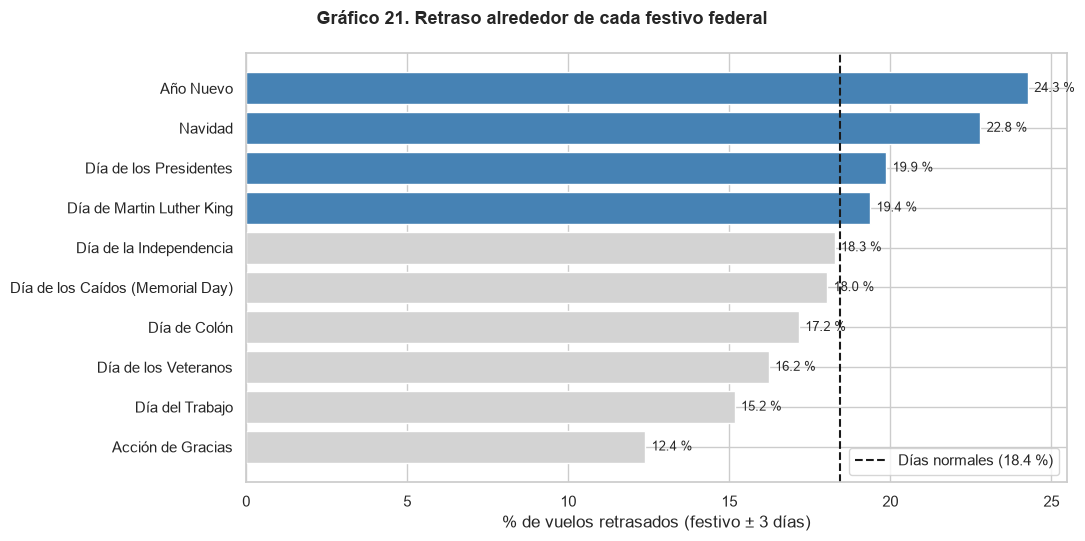

Más retraso: Año Nuevo (24.3 %). Menos retraso: Acción de Gracias (12.4 %). Días normales: 18.4 %.


In [13]:
fest = holidays.US(years=ANIOS)
NOMBRES = {"New Year's Day": "Año Nuevo", "Christmas Day": "Navidad", "Washington's Birthday": "Día de los Presidentes",
           "Martin Luther King Jr. Day": "Día de Martin Luther King", "Independence Day": "Día de la Independencia",
           "Memorial Day": "Día de los Caídos (Memorial Day)", "Columbus Day": "Día de Colón",
           "Veterans Day": "Día de los Veteranos", "Labor Day": "Día del Trabajo", "Thanksgiving Day": "Acción de Gracias"}
fechas_f = pd.Series({pd.Timestamp(k): v.replace(" (observed)", "").replace(" (Observed)", "") for k, v in fest.items()})
fechas_f = fechas_f.map(lambda v: NOMBRES.get(v, v))

def festivo_cercano(d):
    dif = (fechas_f.index - d).days
    i = int(np.argmin(np.abs(dif)))
    return int(dif[i]), fechas_f.iloc[i]

cerca = por_dia["FL_DATE"].apply(festivo_cercano)
por_dia["dias_a_festivo"] = [a for a, _ in cerca]
por_dia["festivo_cercano"] = [b for _, b in cerca]
por_dia["ventana"] = np.select([por_dia["dias_a_festivo"] == 0, por_dia["dias_a_festivo"].abs() <= 3],
                               ["Día festivo", "±3 días de un festivo"], "Día normal")

def tasas(g):
    s = g[["vuelos", "operados", "retrasados", "cancelados"]].sum()
    return pd.Series({"días": len(g), "vuelos por día": s["vuelos"] / len(g),
                      "% retraso": s["retrasados"] / s["operados"] * 100, "% cancelación": s["cancelados"] / s["vuelos"] * 100})

t_vent = por_dia.groupby("ventana").apply(tasas).loc[["Día normal", "±3 días de un festivo", "Día festivo"]]
tabla(t_vent.round(2), "Volumen y retraso en días normales y alrededor de festivos")

t_fest = (por_dia[por_dia["dias_a_festivo"].abs() <= 3].groupby("festivo_cercano").apply(tasas)
          .sort_values("% retraso"))
base = t_vent.loc["Día normal", "% retraso"]
fig, ax = plt.subplots(figsize=(11, 5.5))
colores = ["steelblue" if v > base else "lightgray" for v in t_fest["% retraso"]]
ax.barh(t_fest.index, t_fest["% retraso"], color=colores)
ax.axvline(base, ls="--", c="k", label=f"Días normales ({base:.1f} %)")
for y, v in enumerate(t_fest["% retraso"]):
    ax.text(v + 0.2, y, f"{v:.1f} %", va="center", fontsize=9)
ax.set(xlabel="% de vuelos retrasados (festivo ± 3 días)", ylabel=""); ax.legend(loc="lower right")
grafico(fig, "Retraso alrededor de cada festivo federal")
HALLAZGOS["retraso_festivos"] = t_fest["% retraso"].round(2).to_dict()
HALLAZGOS["retraso_dia_normal"] = round(float(base), 2)
print(f"Más retraso: {t_fest.index[-1]} ({t_fest['% retraso'].iloc[-1]:.1f} %). "
      f"Menos retraso: {t_fest.index[0]} ({t_fest['% retraso'].iloc[0]:.1f} %). Días normales: {base:.1f} %.")

## 4. Contexto 3: eventos extremos

Unos pocos días concentran gran parte de las cancelaciones. Se listan los días con más cancelaciones y su causa dominante; luego se contrastan con eventos conocidos (tormentas invernales, huracanes, fallas en aeropuertos). Estos días deben tratarse aparte: un promedio que los incluye mezcla la operación normal con situaciones de crisis.

Tabla 7. Los 15 días con más cancelaciones


,vuelos,tasa_cancelacion,tasa_retraso,causa_dominante,% cancelaciones por clima
FL_DATE,,,,,
2017-03-14,15968,25.03,24.79,Clima,96.07
2016-01-23,11732,24.45,16.58,Clima,95.47
2018-01-04,19239,20.14,16.23,Clima,90.24
2018-03-21,20369,20.08,20.96,Clima,89.32
2017-09-11,16440,19.36,12.75,Clima,97.80
2016-01-24,14001,17.88,13.61,Clima,92.17
2018-03-02,20218,15.89,22.62,Clima,86.36
2017-02-09,15442,15.06,22.65,Clima,91.01
2016-01-22,15290,14.82,25.21,Clima,92.63


62 días (5.7% de los días) tienen más de 5 % de cancelaciones y concentran el 35.7 % de todas las cancelaciones.


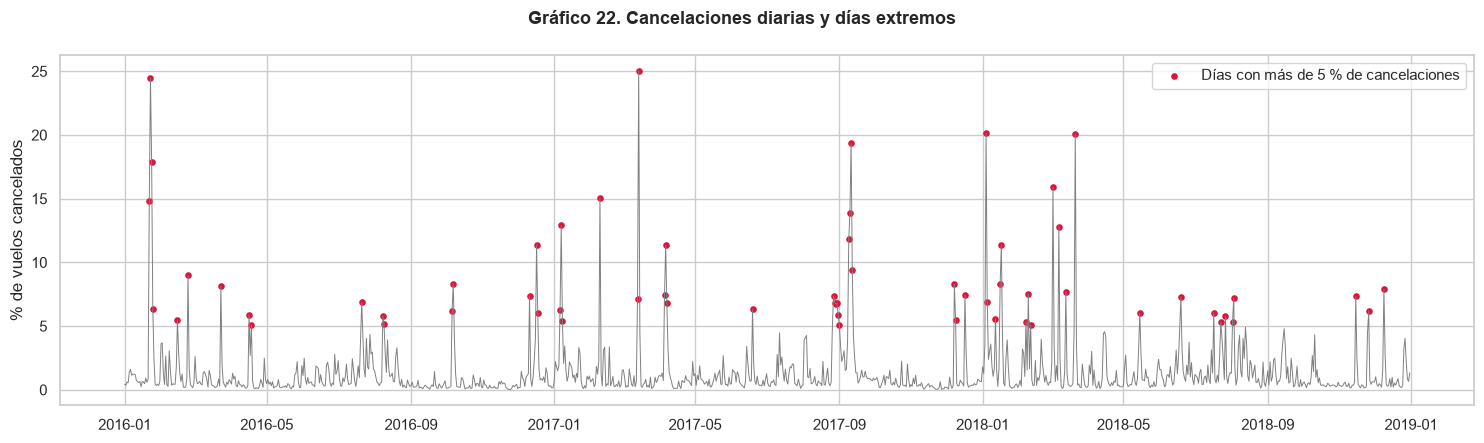

In [14]:
mapa = {"A": "Aerolínea", "B": "Clima", "C": "Sistema aéreo (NAS)", "D": "Seguridad"}
canc_dia.columns = [mapa.get(str(c), str(c)) for c in canc_dia.columns]
causa_dom = canc_dia.idxmax(axis=1).rename("causa_dominante")
pct_clima = (canc_dia.get("Clima", 0) / canc_dia.sum(axis=1) * 100).rename("% cancelaciones por clima")
por_dia = por_dia.join(causa_dom, on="FL_DATE").join(pct_clima, on="FL_DATE")

peores = (por_dia.nlargest(15, "tasa_cancelacion")
          [["FL_DATE", "vuelos", "tasa_cancelacion", "tasa_retraso", "causa_dominante", "% cancelaciones por clima"]]
          .assign(FL_DATE=lambda t: t["FL_DATE"].dt.strftime("%Y-%m-%d")).set_index("FL_DATE"))
tabla(peores.round(2), "Los 15 días con más cancelaciones")

extremos = por_dia["tasa_cancelacion"] > 5
total_canc = por_dia["cancelados"].sum()
HALLAZGOS["dias_cancelacion_mayor_5pct"] = int(extremos.sum())
HALLAZGOS["pct_cancelaciones_en_esos_dias"] = round(float(por_dia.loc[extremos, "cancelados"].sum() / total_canc * 100), 1)
print(f"{extremos.sum()} días ({extremos.mean():.1%} de los días) tienen más de 5 % de cancelaciones "
      f"y concentran el {HALLAZGOS['pct_cancelaciones_en_esos_dias']} % de todas las cancelaciones.")

fig, ax = plt.subplots(figsize=(15, 4.5))
ax.plot(por_dia["FL_DATE"], por_dia["tasa_cancelacion"], lw=0.7, color="gray")
ax.scatter(por_dia.loc[extremos, "FL_DATE"], por_dia.loc[extremos, "tasa_cancelacion"], color="crimson", s=14,
           label="Días con más de 5 % de cancelaciones")
ax.set(ylabel="% de vuelos cancelados", xlabel=""); ax.legend()
grafico(fig, "Cancelaciones diarias y días extremos")

## 5. Contexto 4: ubicación de los aeropuertos

La base solo trae el código IATA. Con `airportsdata` se agregan ciudad, estado, coordenadas y zona horaria, y se agrupan los estados en las cuatro regiones del censo de EE. UU.

Aeropuertos sin ubicación: ['ISN', 'PBI', 'TKI']
Tabla 8. Retraso y cancelación por región


,vuelos,% retraso,% cancelación,% minutos NAS,% minutos clima
region,,,,,
Noreste,2270649,20.83,2.45,26.71,4.33
Territorios,100806,19.05,2.13,13.01,1.17
Sur,7122214,18.33,1.53,24.00,6.06
Medio Oeste,3239539,18.28,1.45,25.09,5.93
Oeste,5769917,17.58,0.90,23.73,2.75


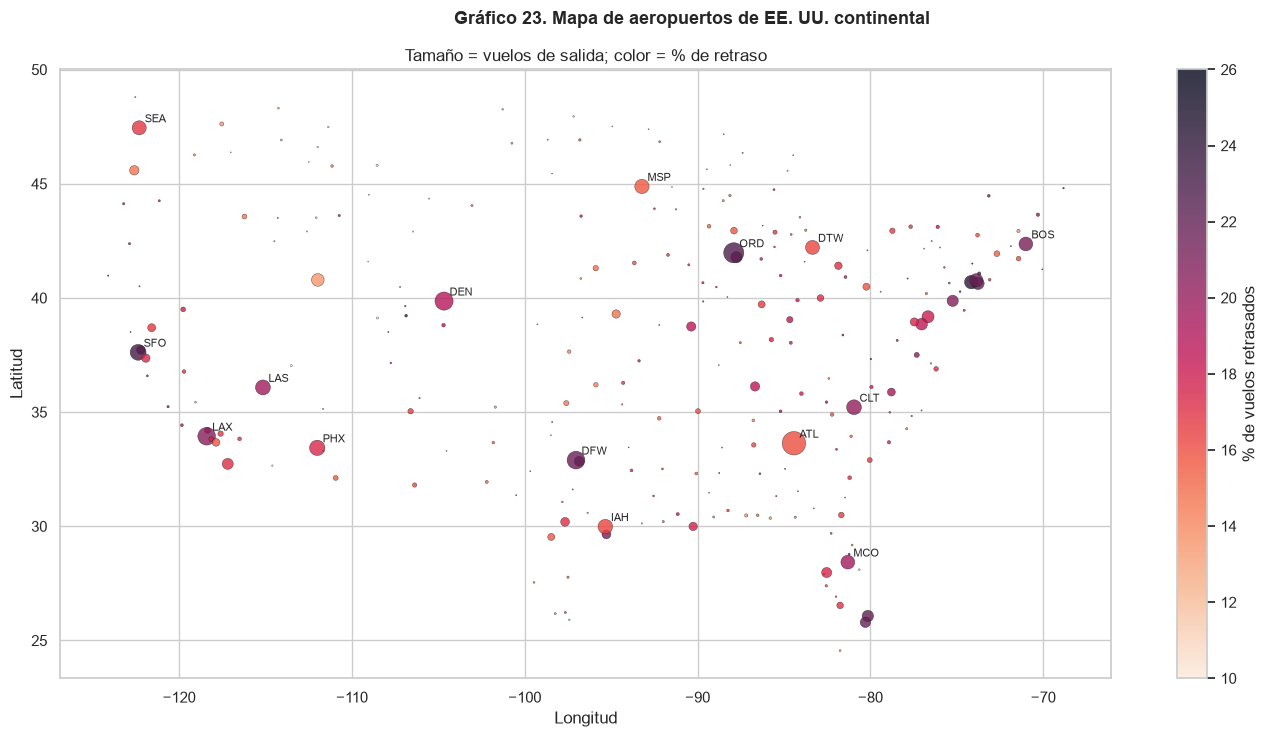

In [15]:
AP = airportsdata.load("IATA")
CORRECCIONES = {"PBI": "Florida", "ISN": "North Dakota"}     # códigos sin estado en la librería
REGIONES = {
    "Noreste": ["Connecticut", "Maine", "Massachusetts", "New Hampshire", "Rhode Island", "Vermont",
                "New Jersey", "New York", "Pennsylvania"],
    "Medio Oeste": ["Illinois", "Indiana", "Michigan", "Ohio", "Wisconsin", "Iowa", "Kansas", "Minnesota",
                    "Missouri", "Nebraska", "North Dakota", "South Dakota"],
    "Sur": ["Delaware", "Florida", "Georgia", "Maryland", "North Carolina", "South Carolina", "Virginia",
            "District of Columbia", "West Virginia", "Alabama", "Kentucky", "Mississippi", "Tennessee",
            "Arkansas", "Louisiana", "Oklahoma", "Texas"],
    "Oeste": ["Arizona", "Colorado", "Idaho", "Montana", "Nevada", "New Mexico", "Utah", "Wyoming",
              "Alaska", "California", "Hawaii", "Oregon", "Washington"],
}
EST_REG = {e: r for r, lista in REGIONES.items() for e in lista}

pa = por_aeropuerto.copy()
pa["ORIGIN"] = pa["ORIGIN"].astype(str)
pa["ciudad"] = pa["ORIGIN"].map(lambda c: AP.get(c, {}).get("city"))
pa["estado"] = pa["ORIGIN"].map(lambda c: CORRECCIONES.get(c) or AP.get(c, {}).get("subd") or None)
pa["lat"] = pa["ORIGIN"].map(lambda c: AP.get(c, {}).get("lat"))
pa["lon"] = pa["ORIGIN"].map(lambda c: AP.get(c, {}).get("lon"))
pa["zona_horaria"] = pa["ORIGIN"].map(lambda c: AP.get(c, {}).get("tz"))
pa["region"] = pa["estado"].map(EST_REG).fillna("Territorios")
print("Aeropuertos sin ubicación:", pa.loc[pa["lat"].isna(), "ORIGIN"].tolist())

reg = pa.groupby("region")[["vuelos", "operados", "retrasados", "cancelados"] + [f"min_{c}" for c in CAUSAS]].sum()
t_reg = pd.DataFrame({
    "vuelos": reg["vuelos"],
    "% retraso": reg["retrasados"] / reg["operados"] * 100,
    "% cancelación": reg["cancelados"] / reg["vuelos"] * 100,
    "% minutos NAS": reg["min_NAS_DELAY"] / reg[[f"min_{c}" for c in CAUSAS]].sum(axis=1) * 100,
    "% minutos clima": reg["min_WEATHER_DELAY"] / reg[[f"min_{c}" for c in CAUSAS]].sum(axis=1) * 100,
}).sort_values("% retraso", ascending=False)
tabla(t_reg.round(2), "Retraso y cancelación por región")
HALLAZGOS["por_region"] = t_reg[["% retraso", "% cancelación"]].round(2).to_dict()

m = pa[(pa["lon"] > -130) & (pa["lat"] > 23) & (pa["lat"] < 50) & (pa["vuelos"] > 2000)]   # EE. UU. continental
fig, ax = plt.subplots(figsize=(14, 7.5))
sc = ax.scatter(m["lon"], m["lat"], s=m["vuelos"] / 4000, c=m["tasa_retraso"], cmap="rocket_r",
                vmin=10, vmax=26, alpha=0.8, edgecolor="k", linewidth=0.3)
for _, r in m.nlargest(15, "vuelos").iterrows():
    ax.annotate(r["ORIGIN"], (r["lon"], r["lat"]), fontsize=8, xytext=(4, 4), textcoords="offset points")
plt.colorbar(sc, label="% de vuelos retrasados")
ax.set(xlabel="Longitud", ylabel="Latitud", title="Tamaño = vuelos de salida; color = % de retraso")
grafico(fig, "Mapa de aeropuertos de EE. UU. continental")

## 6. Contexto 5: clima diario en los aeropuertos principales

La base solo atribuye al clima el **4,8 %** de los minutos de retraso, porque esa columna registra únicamente el clima *extremo*; el mal tiempo común queda dentro del sistema aéreo (NAS). Para medir su efecto real se descarga el clima diario (precipitación, nieve, viento y temperatura) de la estación meteorológica más cercana a cada uno de los 30 aeropuertos con más vuelos y se cruza con el retraso de ese aeropuerto ese día.

Esta sección necesita internet. Si falla, el resto del notebook sigue funcionando.

In [16]:
clima_ok = False
try:
    from datetime import datetime
    from meteostat import Daily, Point
    partes = []
    for cod in top_ap:
        info = AP.get(cod)
        if not info:
            continue
        w = Daily(Point(info["lat"], info["lon"], int(info.get("elevation") or 0) // 3),
                  datetime(min(ANIOS), 1, 1), datetime(max(ANIOS), 12, 31)).fetch()
        if w.empty:
            print(f"Sin datos de clima para {cod}")
            continue
        w = w[["tavg", "prcp", "snow", "wspd"]].reset_index().rename(columns={"time": "FL_DATE"})
        w["ORIGIN"] = cod
        partes.append(w)
    clima = pd.concat(partes, ignore_index=True)
    clima_ok = True
    print(f"Clima descargado para {clima['ORIGIN'].nunique()} aeropuertos ({len(clima):,} días-aeropuerto)")
except Exception as e:
    print("No se pudo descargar el clima:", type(e).__name__, str(e)[:200])
    print("Se omite esta sección. Revise la conexión o instale: pip install \"meteostat<2\"")

Clima descargado para 30 aeropuertos (32,880 días-aeropuerto)


Tabla 9. Retraso según la lluvia del día en el aeropuerto


,días-aeropuerto,% retraso,% cancelación
lluvia,,,
Sin lluvia,23200,16.44,0.85
0-5 mm,5355,22.97,1.47
5-20 mm,3052,29.52,3.24
Más de 20 mm,1273,36.52,7.11


Tabla 10. Retraso según la nieve en el aeropuerto


,días-aeropuerto,% retraso,% cancelación
nieve,,,
Con nieve en el suelo,1049,27.30,5.55
Sin nieve,31831,19.07,1.26


Tabla 11. Retraso según la velocidad del viento


,días-aeropuerto,% retraso,% cancelación
viento,,,
< 15 km/h,21160,18.19,1.06
15-30 km/h,11150,21.05,1.65
> 30 km/h,569,27.98,8.77


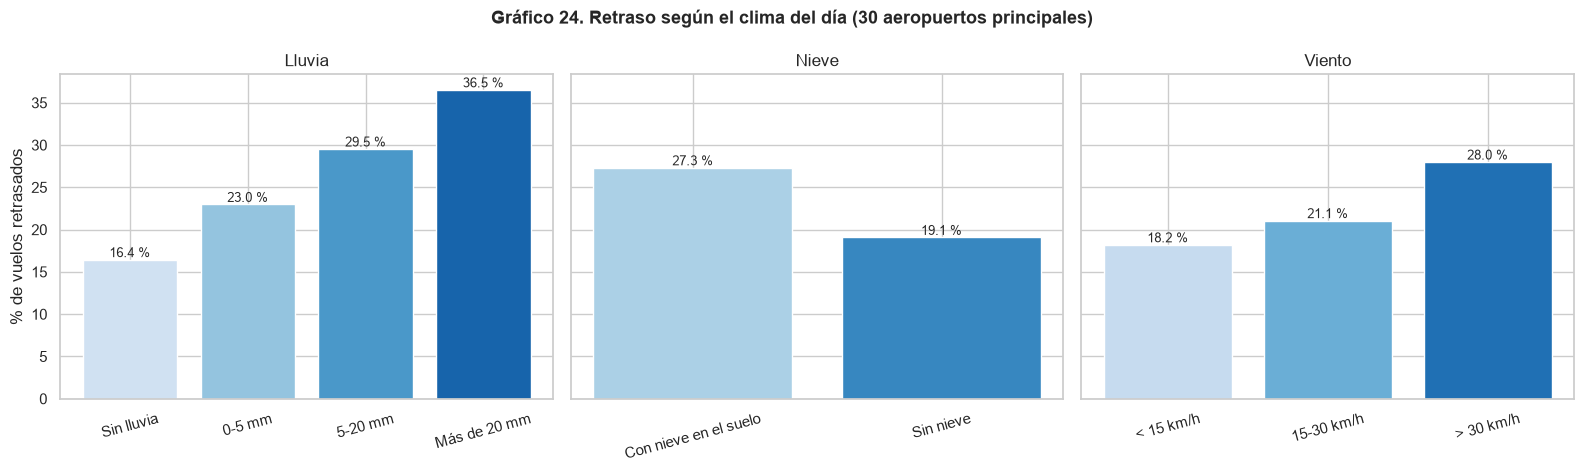

{'retraso_sin_lluvia': 16.44, 'retraso_lluvia_fuerte': 36.52, 'spearman_lluvia_retraso': 0.34, 'spearman_viento_retraso': 0.16}


In [17]:
if clima_ok:
    ap_dia["ORIGIN"] = ap_dia["ORIGIN"].astype(str)
    x = ap_dia.merge(clima, on=["ORIGIN", "FL_DATE"], how="inner")
    x["lluvia"] = pd.cut(x["prcp"].fillna(0), [-0.1, 0, 5, 20, np.inf],
                         labels=["Sin lluvia", "0-5 mm", "5-20 mm", "Más de 20 mm"])
    x["nieve"] = np.where(x["snow"].fillna(0) > 0, "Con nieve en el suelo", "Sin nieve")
    x["viento"] = pd.cut(x["wspd"], [-0.1, 15, 30, np.inf], labels=["< 15 km/h", "15-30 km/h", "> 30 km/h"])

    def tasa_grupo(col):
        g = x.groupby(col, observed=True)[["operados", "retrasados", "cancelados", "vuelos"]].sum()
        return pd.DataFrame({"días-aeropuerto": x.groupby(col, observed=True).size(),
                             "% retraso": g["retrasados"] / g["operados"] * 100,
                             "% cancelación": g["cancelados"] / g["vuelos"] * 100})

    t_lluvia, t_nieve, t_viento = tasa_grupo("lluvia"), tasa_grupo("nieve"), tasa_grupo("viento")
    tabla(t_lluvia.round(2), "Retraso según la lluvia del día en el aeropuerto")
    tabla(t_nieve.round(2), "Retraso según la nieve en el aeropuerto")
    tabla(t_viento.round(2), "Retraso según la velocidad del viento")

    fig, ax = plt.subplots(1, 3, figsize=(16, 4.8), sharey=True)
    for a, (t, nombre) in zip(ax, [(t_lluvia, "Lluvia"), (t_nieve, "Nieve"), (t_viento, "Viento")]):
        a.bar(t.index.astype(str), t["% retraso"], color=sns.color_palette("Blues", len(t)))
        a.set(title=nombre, xlabel=""); a.tick_params(axis="x", rotation=15)
        for i, v in enumerate(t["% retraso"]):
            a.text(i, v + 0.3, f"{v:.1f} %", ha="center", fontsize=9)
    ax[0].set_ylabel("% de vuelos retrasados")
    grafico(fig, "Retraso según el clima del día (30 aeropuertos principales)")

    corr = x[["tasa_retraso", "tasa_cancelacion", "prcp", "snow", "wspd", "tavg"]].corr(method="spearman")
    HALLAZGOS["clima"] = {
        "retraso_sin_lluvia": round(float(t_lluvia["% retraso"].iloc[0]), 2),
        "retraso_lluvia_fuerte": round(float(t_lluvia["% retraso"].iloc[-1]), 2),
        "spearman_lluvia_retraso": round(float(corr.loc["prcp", "tasa_retraso"]), 2),
        "spearman_viento_retraso": round(float(corr.loc["wspd", "tasa_retraso"]), 2),
    }
    print(HALLAZGOS["clima"])
    x.to_csv(OUT_DIR / "aeropuerto_dia_clima.csv", index=False)

## 7. Resumen: ¿se requiere información adicional?

Sí. La base es suficiente para describir **cuándo y dónde** hay retraso, pero necesita contexto externo para explicar **por qué**. Se guardan las tablas enriquecidas para usarlas en Prefect, AWS y Grafana.

In [18]:
por_dia.to_csv(OUT_DIR / "dias_con_contexto.csv", index=False)
pa.to_csv(OUT_DIR / "aeropuertos_con_contexto.csv", index=False)
por_aerolinea.to_csv(OUT_DIR / "aerolineas_con_contexto.csv", index=False)
AEROLINEAS.to_csv(OUT_DIR / "catalogo_aerolineas.csv")

necesidad = pd.DataFrame([
    ("Tipo y marca de aerolínea", "Integrada", "Explica diferencias por modelo de negocio y atribución de regionales"),
    ("Festivos federales", "Integrada", "Cambia volumen y retraso según el festivo"),
    ("Eventos extremos", "Identificada", "Pocos días concentran gran parte de las cancelaciones"),
    ("Ubicación de aeropuertos", "Integrada", "Permite comparar regiones y construir mapas"),
    ("Clima diario por aeropuerto", "Integrada" if clima_ok else "Pendiente (sin conexión)",
     "La columna de clima de la base solo cubre clima extremo"),
], columns=["Información adicional", "Estado", "Por qué se necesita"]).set_index("Información adicional")
tabla(necesidad, "Información adicional de contexto")

with open(OUT_DIR / "hallazgos_contexto.json", "w", encoding="utf-8") as f:
    json.dump(HALLAZGOS, f, ensure_ascii=False, indent=2, default=str)
print(json.dumps(HALLAZGOS, ensure_ascii=False, indent=2, default=str))

Tabla 12. Información adicional de contexto


,Estado,Por qué se necesita
Información adicional,,
Tipo y marca de aerolínea,Integrada,Explica diferencias por modelo de negocio y at...
Festivos federales,Integrada,Cambia volumen y retraso según el festivo
Eventos extremos,Identificada,Pocos días concentran gran parte de las cancel...
Ubicación de aeropuertos,Integrada,Permite comparar regiones y construir mapas
Clima diario por aeropuerto,Integrada,La columna de clima de la base solo cubre clim...


{
  "tasa_por_tipo": {
    "Bajo costo": 20.82,
    "Regional": 18.81,
    "Tradicional": 16.41
  },
  "pct_avion_retrasado_por_tipo": {
    "Bajo costo": 45.400001525878906,
    "Regional": 39.29999923706055,
    "Tradicional": 34.599998474121094
  },
  "retraso_festivos": {
    "Acción de Gracias": 12.39,
    "Día del Trabajo": 15.17,
    "Día de los Veteranos": 16.22,
    "Día de Colón": 17.16,
    "Día de los Caídos (Memorial Day)": 18.04,
    "Día de la Independencia": 18.27,
    "Día de Martin Luther King": 19.37,
    "Día de los Presidentes": 19.87,
    "Navidad": 22.79,
    "Año Nuevo": 24.27
  },
  "retraso_dia_normal": 18.43,
  "dias_cancelacion_mayor_5pct": 62,
  "pct_cancelaciones_en_esos_dias": 35.7,
  "por_region": {
    "% retraso": {
      "Noreste": 20.83,
      "Territorios": 19.05,
      "Sur": 18.33,
      "Medio Oeste": 18.28,
      "Oeste": 17.58
    },
    "% cancelación": {
      "Noreste": 2.45,
      "Territorios": 2.13,
      "Sur": 1.53,
      "Medio Oeste":